In [1]:
!pip install -q imbalanced-learn openpyxl
from google.colab import files
uploaded = files.upload()
PATH = list(uploaded.keys())[0]   # otomatis memakai nama file yang diupload
print("File dipakai:", PATH)

Saving FSVA_Data_Nasional_2025(1).xlsx to FSVA_Data_Nasional_2025(1) (2).xlsx
File dipakai: FSVA_Data_Nasional_2025(1) (2).xlsx


Ukuran data       : (514, 31)
Tahun             : [2025]
Jumlah provinsi   : 38
Jumlah kab/kota   : 514 (nama unik)

Tipe data fitur:
float64    12
Name: count, dtype: int64

Nilai kosong pada fitur & target:
Tidak ada nilai kosong.
Baris duplikat penuh : 0
Kode wilayah duplikat: 0

Statistik deskriptif indikator:
            mean    std    min    25%    50%     75%    max  skewness
NCPR        3.34   3.69   0.09   0.65   1.28    5.40   10.0      1.02
ENERGI     95.96   8.89  69.10  90.50  95.85  101.30  120.0      0.09
PROHE      89.30  19.87  28.00  75.43  88.90  105.20  120.0     -0.32
CBPK       38.10  40.83   0.00   0.00  20.40   85.18  100.0      0.55
MISKIN     11.17   7.07   2.20   6.40   9.30   13.80   41.4      1.65
CVHARGA     5.79   2.08   2.00   4.53   5.55    6.60   20.0      2.51
POU        11.08   8.73   0.90   6.20   8.70   12.30   57.9      2.55
RLSP        8.96   1.55   1.89   8.12   8.84    9.82   12.0     -0.76
TNPAIR     27.55  20.26   0.00  13.02  23.95   37.25  

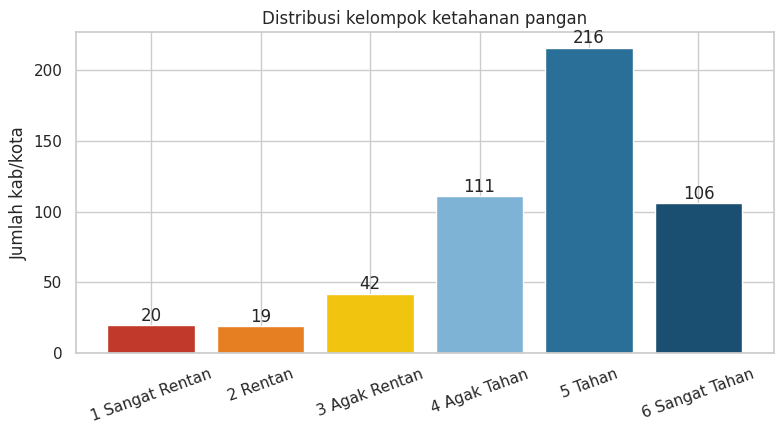

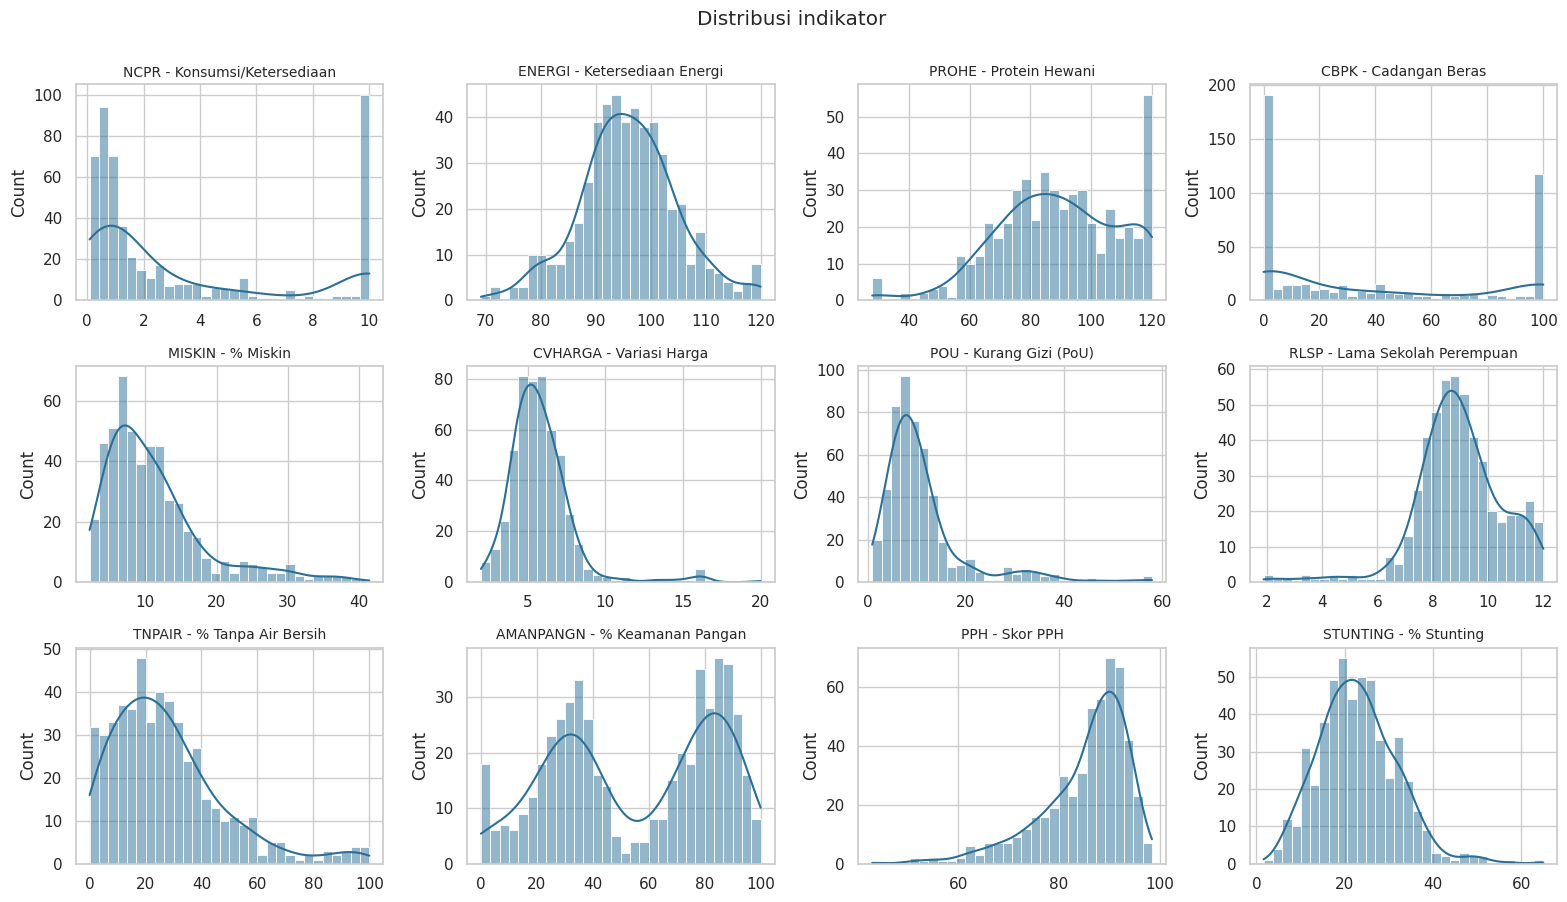


Jumlah outlier per indikator (aturan IQR):
           Outlier  Persen
POU             46     8.9
MISKIN          33     6.4
TNPAIR          20     3.9
PPH             19     3.7
CVHARGA         16     3.1
ENERGI          15     2.9
RLSP            14     2.7
STUNTING         9     1.8
PROHE            5     1.0
NCPR             0     0.0
CBPK             0     0.0
AMANPANGN        0     0.0

CBPK bernilai 0 : 178 daerah (34.6%)


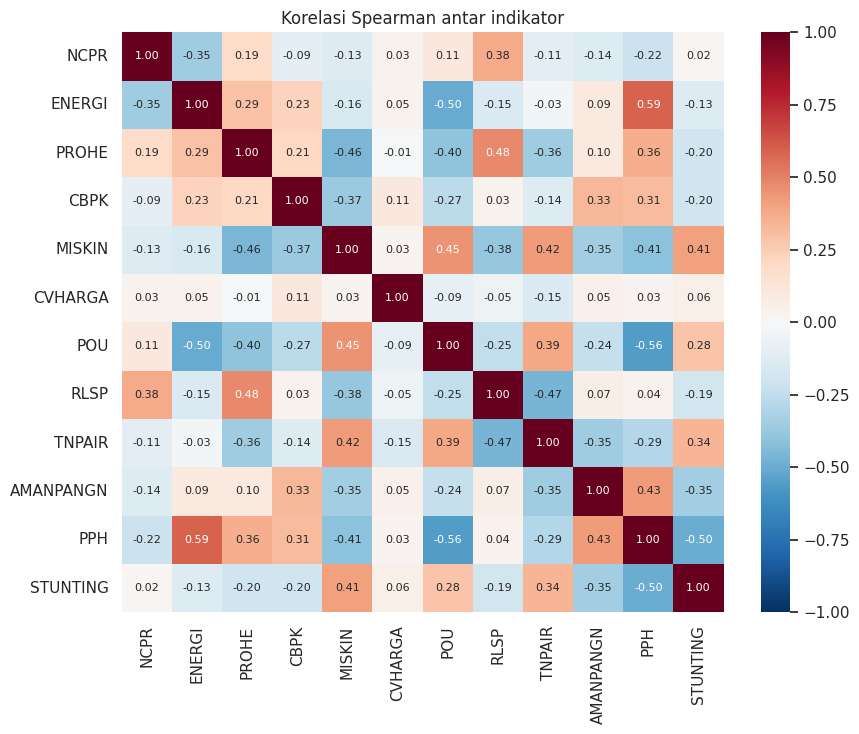


5 pasangan indikator berkorelasi paling kuat:
level_0  level_1  korelasi
 ENERGI      PPH      0.59
    POU      PPH     -0.56
 ENERGI      POU     -0.50
    PPH STUNTING     -0.50
  PROHE     RLSP      0.48

Rata-rata indikator per kelompok:
                 NCPR  ENERGI  PROHE  CBPK  MISKIN  CVHARGA   POU  RLSP  TNPAIR  AMANPANGN   PPH  STUNTING
PKOMP                                                                                                     
1 Sangat Rentan   9.7    84.5   50.8   9.7    32.4      9.0  34.7   5.4    79.4       11.7  64.3      38.8
2 Rentan          7.9    85.3   82.1   7.0    22.0      6.9  26.7   8.8    50.3       22.9  71.1      30.8
3 Agak Rentan     3.9    88.5   71.6   2.3    17.6      5.4  17.7   8.9    36.4       29.4  75.0      31.1
4 Agak Tahan      3.3    93.6   87.8  13.1    11.3      5.7  11.2   9.1    27.3       42.4  82.6      23.9
5 Tahan           2.9    97.9   91.8  42.5     8.9      5.6   8.5   9.1    23.2       64.5  88.8      20.4
6 Sanga

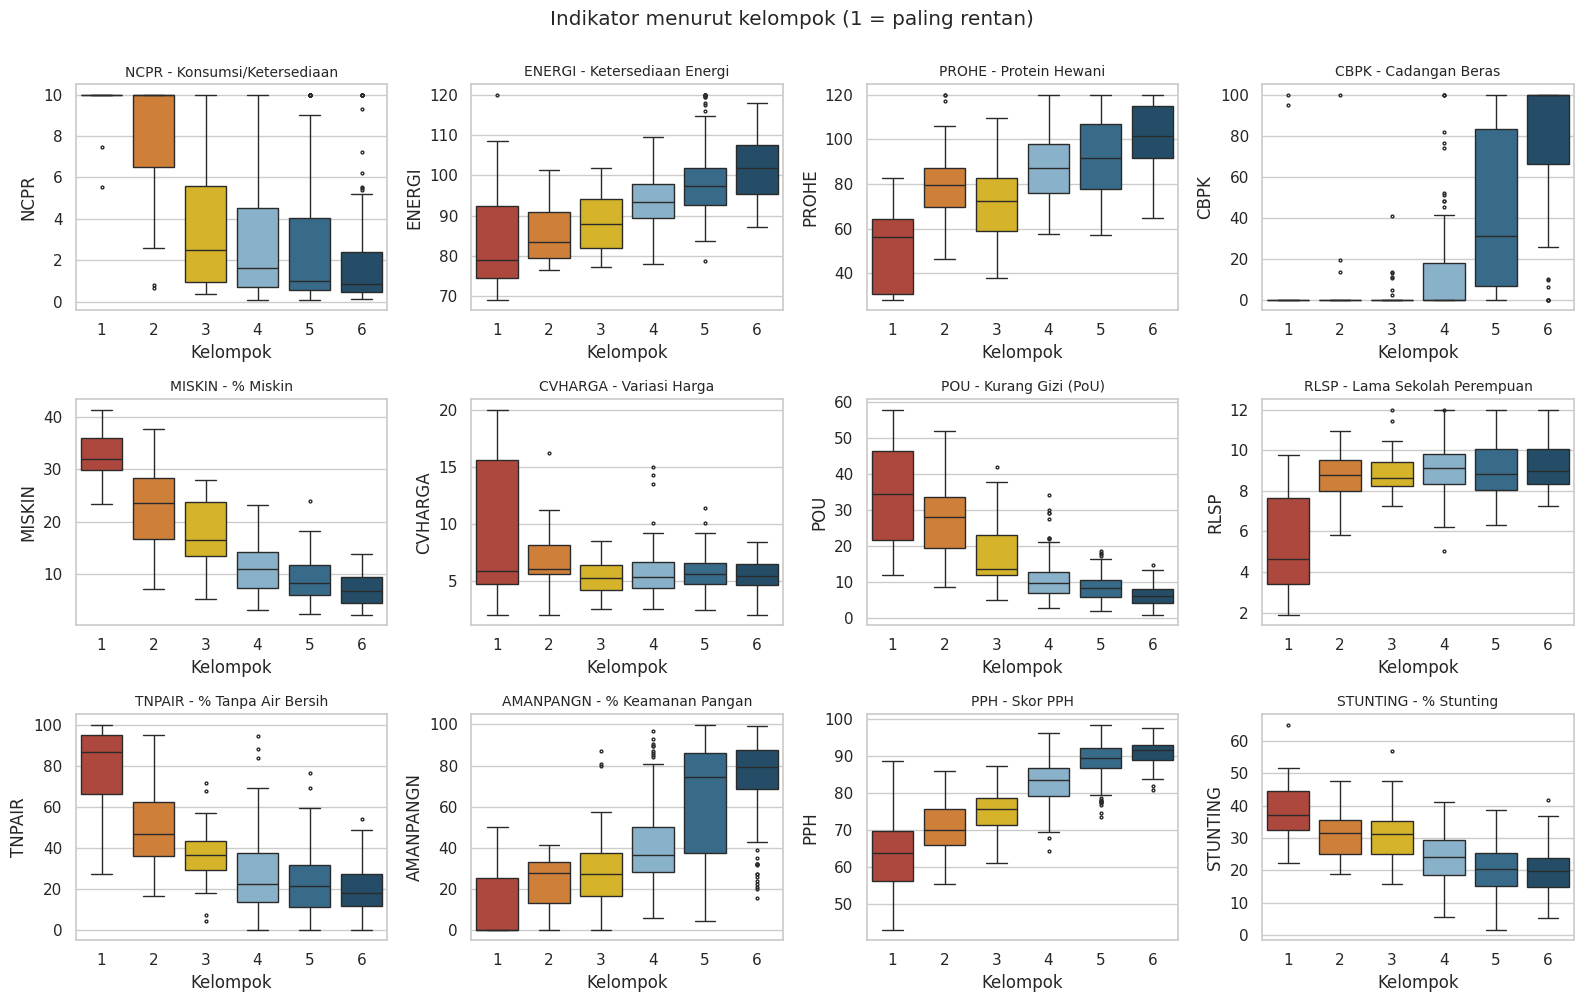


10 provinsi dengan jumlah kab/kota rentan (kelompok 1-3) terbanyak:
                     Jumlah  Rentan  % Rentan
WADMPR                                       
Nusa Tenggara Timur      22      18      81.8
Maluku                   11       9      81.8
Papua Pegunungan          8       8     100.0
Papua                     9       8      88.9
Papua Tengah              8       7      87.5
Maluku Utara             10       6      60.0
Papua Barat Daya          6       5      83.3
Papua Barat               7       5      71.4
Sulawesi Tenggara        17       4      23.5
Papua Selatan             4       3      75.0


In [2]:
# ==============================================================
# EKSPLORASI DATA (EDA) - FSVA Nasional 2025
# ==============================================================
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

# --------------------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------------------
df = pd.read_excel(PATH, header=1)     # baris 1 = nama kolom singkat

FITUR = ["NCPR", "ENERGI", "PROHE", "CBPK", "MISKIN", "CVHARGA",
         "POU", "RLSP", "TNPAIR", "AMANPANGN", "PPH", "STUNTING"]
NAMA = {"NCPR": "Konsumsi/Ketersediaan", "ENERGI": "Ketersediaan Energi",
        "PROHE": "Protein Hewani", "CBPK": "Cadangan Beras",
        "MISKIN": "% Miskin", "CVHARGA": "Variasi Harga",
        "POU": "Kurang Gizi (PoU)", "RLSP": "Lama Sekolah Perempuan",
        "TNPAIR": "% Tanpa Air Bersih", "AMANPANGN": "% Keamanan Pangan",
        "PPH": "Skor PPH", "STUNTING": "% Stunting"}
LABEL = {1: "1 Sangat Rentan", 2: "2 Rentan", 3: "3 Agak Rentan",
         4: "4 Agak Tahan", 5: "5 Tahan", 6: "6 Sangat Tahan"}

# --------------------------------------------------------------
# 2. GAMBARAN UMUM DATA
# --------------------------------------------------------------
print("Ukuran data       :", df.shape)
print("Tahun             :", df["TAHUN"].unique())
print("Jumlah provinsi   :", df["WADMPR"].nunique())
print("Jumlah kab/kota   :", df["WADMKK"].nunique(), "(nama unik)")
print("\nTipe data fitur:")
print(df[FITUR].dtypes.value_counts())

# --------------------------------------------------------------
# 3. KUALITAS DATA: nilai kosong dan duplikat
# --------------------------------------------------------------
print("\nNilai kosong pada fitur & target:")
print(df[FITUR + ["PKOMP"]].isna().sum().loc[lambda s: s > 0]
      if df[FITUR + ["PKOMP"]].isna().any().any() else "Tidak ada nilai kosong.")
print("Baris duplikat penuh :", df.duplicated().sum())
print("Kode wilayah duplikat:", df["KDPKAB"].duplicated().sum())

# --------------------------------------------------------------
# 4. STATISTIK DESKRIPTIF
# --------------------------------------------------------------
desk = df[FITUR].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desk["skewness"] = df[FITUR].skew()
print("\nStatistik deskriptif indikator:")
print(desk.round(2))

# --------------------------------------------------------------
# 5. DISTRIBUSI KELOMPOK (TARGET)
# --------------------------------------------------------------
dist = df["PKOMP"].value_counts().sort_index()
print("\nDistribusi kelompok PKOMP:")
print(pd.DataFrame({"Jumlah": dist, "Persen": (dist / dist.sum() * 100).round(1)})
      .rename(index=LABEL))
print("Rasio kelas terbesar : terkecil =", round(dist.max() / dist.min(), 1), ": 1")

fig, ax = plt.subplots(figsize=(8, 4.5))
warna = ["#c0392b", "#e67e22", "#f1c40f", "#7fb3d5", "#2a6f97", "#1b4f72"]
ax.bar([LABEL[i] for i in dist.index], dist.values, color=warna)
for i, v in enumerate(dist.values):
    ax.text(i, v + 3, f"{v}", ha="center")
ax.set_ylabel("Jumlah kab/kota"); ax.set_title("Distribusi kelompok ketahanan pangan")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("eda_distribusi_kelas.png", dpi=150); plt.show()

# --------------------------------------------------------------
# 6. DISTRIBUSI SETIAP INDIKATOR (histogram)
# --------------------------------------------------------------
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, f in zip(axes.ravel(), FITUR):
    sns.histplot(df[f], bins=30, kde=True, ax=ax, color="#2a6f97")
    ax.set_title(f"{f} - {NAMA[f]}", fontsize=10); ax.set_xlabel("")
plt.suptitle("Distribusi indikator", y=1.00); plt.tight_layout()
plt.savefig("eda_histogram.png", dpi=150); plt.show()

# --------------------------------------------------------------
# 7. OUTLIER (aturan IQR) - hanya untuk dipahami, tidak dihapus
# --------------------------------------------------------------
q1, q3 = df[FITUR].quantile(0.25), df[FITUR].quantile(0.75)
iqr = q3 - q1
out = ((df[FITUR] < q1 - 1.5 * iqr) | (df[FITUR] > q3 + 1.5 * iqr)).sum()
print("\nJumlah outlier per indikator (aturan IQR):")
print(out.sort_values(ascending=False).to_frame("Outlier")
      .assign(Persen=lambda d: (d["Outlier"] / len(df) * 100).round(1)))
print("\nCBPK bernilai 0 :", (df["CBPK"] == 0).sum(), "daerah",
      f"({(df['CBPK'] == 0).mean() * 100:.1f}%)")

# --------------------------------------------------------------
# 8. KORELASI ANTAR INDIKATOR
# --------------------------------------------------------------
korelasi = df[FITUR].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Korelasi Spearman antar indikator")
plt.tight_layout(); plt.savefig("eda_korelasi.png", dpi=150); plt.show()

pasangan = (korelasi.where(np.triu(np.ones(korelasi.shape), k=1).astype(bool))
            .stack().rename("korelasi").reset_index())
pasangan["abs"] = pasangan["korelasi"].abs()
print("\n5 pasangan indikator berkorelasi paling kuat:")
print(pasangan.sort_values("abs", ascending=False).head(5)
      .drop(columns="abs").round(2).to_string(index=False))

# --------------------------------------------------------------
# 9. INDIKATOR vs KELOMPOK: apakah indikator membedakan kelompok?
# --------------------------------------------------------------
rata = df.groupby("PKOMP")[FITUR].mean().round(1)
print("\nRata-rata indikator per kelompok:")
print(rata.rename(index=LABEL))

kor_target = df[FITUR].corrwith(df["PKOMP"], method="spearman").sort_values()
print("\nKorelasi indikator dengan kelompok PKOMP (Spearman):")
print(kor_target.round(2))

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, f in zip(axes.ravel(), FITUR):
    sns.boxplot(data=df, x="PKOMP", y=f, ax=ax, palette=warna, fliersize=2)
    ax.set_title(f"{f} - {NAMA[f]}", fontsize=10); ax.set_xlabel("Kelompok")
plt.suptitle("Indikator menurut kelompok (1 = paling rentan)", y=1.00)
plt.tight_layout(); plt.savefig("eda_boxplot_kelompok.png", dpi=150); plt.show()

# --------------------------------------------------------------
# 10. SEBARAN PER PROVINSI: kelompok rentan (1-3) terbanyak
# --------------------------------------------------------------
df["Rentan"] = df["PKOMP"] <= 3
prov = (df.groupby("WADMPR")
          .agg(Jumlah=("PKOMP", "size"), Rentan=("Rentan", "sum")))
prov["% Rentan"] = (prov["Rentan"] / prov["Jumlah"] * 100).round(1)
print("\n10 provinsi dengan jumlah kab/kota rentan (kelompok 1-3) terbanyak:")
print(prov.sort_values(["Rentan", "% Rentan"], ascending=False).head(10))

In [3]:
# ==============================================================
# SVM untuk Klasifikasi Ketahanan Pangan Kab/Kota (FSVA 2025)
#  - Target 6 kelas (PKOMP) dan 2 kelas (Rentan vs Tahan)
#  - Perbandingan penanganan imbalance: tanpa penanganan,
#    class_weight, dan SMOTE
#  - Nested cross-validation pada seluruh data (tanpa data leakage)
# ==============================================================
# Di Colab, jalankan sekali:  !pip install -q imbalanced-learn openpyxl
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42

In [4]:
# --------------------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------------------
# Hanya indikator MENTAH. Kolom P*, IKP, RANK tidak dipakai (data leakage).
FITUR = ["NCPR", "ENERGI", "PROHE", "CBPK", "MISKIN", "CVHARGA",
         "POU", "RLSP", "TNPAIR", "AMANPANGN", "PPH", "STUNTING"]
df = df.dropna(subset=FITUR + ["PKOMP"]).reset_index(drop=True)
X = df[FITUR]
y6 = df["PKOMP"].astype(int)                                  # 6 kelas
y2 = np.where(y6 <= 3, "Rentan", "Tahan")                     # 2 kelas
y2 = pd.Series(y2, index=df.index)

print("Ukuran data:", X.shape)
print("\nDistribusi 6 kelas (1 = paling rentan, 6 = paling tahan):")
print(y6.value_counts().sort_index())
print("\nDistribusi 2 kelas:")
print(y2.value_counts(), "\n", (y2.value_counts(normalize=True) * 100).round(1))

Ukuran data: (514, 12)

Distribusi 6 kelas (1 = paling rentan, 6 = paling tahan):
PKOMP
1     20
2     19
3     42
4    111
5    216
6    106
Name: count, dtype: int64

Distribusi 2 kelas:
Tahan     433
Rentan     81
Name: count, dtype: int64 
 Tahan     84.2
Rentan    15.8
Name: proportion, dtype: float64


In [5]:
# --------------------------------------------------------------
# 2. PIPELINE PER STRATEGI IMBALANCE
# --------------------------------------------------------------
def buat_model(strategi):
    if strategi == "Tanpa penanganan":
        return Pipeline([("scaler", StandardScaler()), ("svm", SVC())])
    if strategi == "Class weight":
        return Pipeline([("scaler", StandardScaler()),
                         ("svm", SVC(class_weight="balanced"))])
    if strategi == "SMOTE":   # SMOTE hanya dijalankan pada data latih tiap fold
        return ImbPipeline([("scaler", StandardScaler()),
                            ("smote", SMOTE(k_neighbors=3, random_state=SEED)),
                            ("svm", SVC())])

PARAM = [
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10, 100],
     "svm__gamma": ["scale", 0.01, 0.1]},
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
]

In [6]:
# --------------------------------------------------------------
# 3. NESTED CROSS-VALIDATION
#    Luar (5 fold): estimasi kinerja. Dalam (3 fold): tuning parameter.
# --------------------------------------------------------------
def nested_cv(X, y, strategi, ambil_importance=False):
    luar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    pred = pd.Series(index=y.index, dtype=object)
    imp = []
    for tr, te in luar.split(X, y):
        dalam = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
        gs = GridSearchCV(buat_model(strategi), PARAM, cv=dalam,
                          scoring="f1_macro", n_jobs=-1)
        gs.fit(X.iloc[tr], y.iloc[tr])
        pred.iloc[te] = gs.predict(X.iloc[te])
        if ambil_importance:
            pi = permutation_importance(gs.best_estimator_, X.iloc[te], y.iloc[te],
                                        n_repeats=10, random_state=SEED,
                                        scoring="f1_macro", n_jobs=-1)
            imp.append(pi.importances_mean)
    return pred.astype(y.dtype), (np.mean(imp, axis=0) if ambil_importance else None)

STRATEGI = ["Tanpa penanganan", "Class weight", "SMOTE"]

def bandingkan(y, nama, pos_label=None):
    baris, preds = [], {}
    for s in STRATEGI:
        p, _ = nested_cv(X, y, s)
        preds[s] = p
        r = {"Strategi": s,
             "Akurasi": accuracy_score(y, p),
             "Balanced Acc": balanced_accuracy_score(y, p),
             "F1-macro": f1_score(y, p, average="macro")}
        if pos_label:
            r["F1 Rentan"] = f1_score(y, p, pos_label=pos_label)
        baris.append(r)
    tabel = pd.DataFrame(baris).set_index("Strategi").round(4)
    print(f"\n===== PERBANDINGAN STRATEGI - {nama} (nested 5-fold CV, seluruh data) =====")
    print(tabel)
    return tabel, preds

tab6, pred6 = bandingkan(y6, "6 KELAS")
tab2, pred2 = bandingkan(y2, "2 KELAS (Rentan vs Tahan)", pos_label="Rentan")


===== PERBANDINGAN STRATEGI - 6 KELAS (nested 5-fold CV, seluruh data) =====
                  Akurasi  Balanced Acc  F1-macro
Strategi                                         
Tanpa penanganan   0.9222        0.8936    0.9002
Class weight       0.8988        0.8738    0.8657
SMOTE              0.9086        0.8892    0.8860

===== PERBANDINGAN STRATEGI - 2 KELAS (Rentan vs Tahan) (nested 5-fold CV, seluruh data) =====
                  Akurasi  Balanced Acc  F1-macro  F1 Rentan
Strategi                                                    
Tanpa penanganan   0.9883        0.9830    0.9782     0.9634
Class weight       0.9883        0.9780    0.9780     0.9630
SMOTE              0.9903        0.9842    0.9818     0.9693



===== DETAIL 6 Kelas | strategi terbaik: Tanpa penanganan =====
              precision    recall  f1-score   support

           1       1.00      0.95      0.97        20
           2       0.83      0.79      0.81        19
           3       0.81      0.83      0.82        42
           4       0.92      0.89      0.90       111
           5       0.94      0.95      0.94       216
           6       0.94      0.94      0.94       106

    accuracy                           0.92       514
   macro avg       0.91      0.89      0.90       514
weighted avg       0.92      0.92      0.92       514



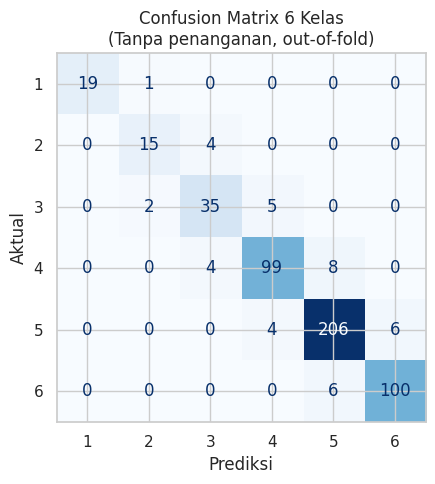


===== DETAIL 2 Kelas | strategi terbaik: SMOTE =====
              precision    recall  f1-score   support

      Rentan       0.96      0.98      0.97        81
       Tahan       1.00      0.99      0.99       433

    accuracy                           0.99       514
   macro avg       0.98      0.98      0.98       514
weighted avg       0.99      0.99      0.99       514



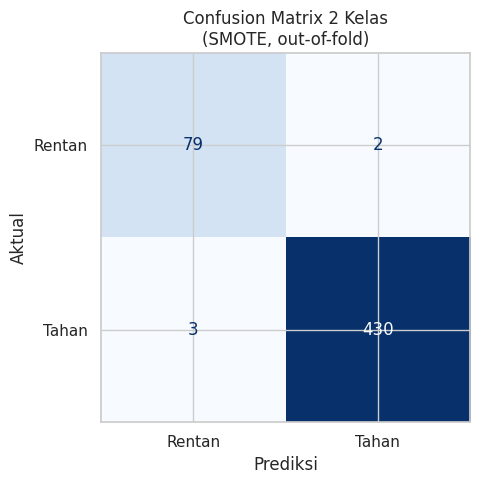

In [7]:
# --------------------------------------------------------------
# 4. LAPORAN DETAIL STRATEGI TERBAIK (berdasarkan F1-macro)
# --------------------------------------------------------------
def detail(y, pred, tabel, nama, nama_file):
    terbaik = tabel["F1-macro"].idxmax()
    p = pred[terbaik]
    print(f"\n===== DETAIL {nama} | strategi terbaik: {terbaik} =====")
    print(classification_report(y, p, zero_division=0))
    lab = sorted(y.unique())
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(confusion_matrix(y, p, labels=lab),
                           display_labels=lab).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix {nama}\n({terbaik}, out-of-fold)")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    plt.tight_layout(); plt.savefig(nama_file, dpi=150); plt.show()
    return terbaik, p

terbaik6, p6 = detail(y6, pred6, tab6, "6 Kelas", "cm_6kelas.png")
terbaik2, p2 = detail(y2, pred2, tab2, "2 Kelas", "cm_2kelas.png")


In [8]:
# --------------------------------------------------------------
# 5. ANALISIS KESALAHAN (6 kelas)
# --------------------------------------------------------------
hasil = df[["WADMPR", "WADMKK"]].copy()
hasil["Aktual"], hasil["Prediksi"] = y6.values, p6.values
salah = hasil[hasil["Aktual"] != hasil["Prediksi"]]
print(f"\nSalah prediksi: {len(salah)} dari {len(hasil)} daerah")
print("Selisih kelompok |aktual - prediksi|:")
print((salah["Aktual"] - salah["Prediksi"]).abs().value_counts().sort_index())
print("\nContoh daerah yang salah prediksi:")
print(salah.head(15).to_string(index=False))
print("\nProvinsi dengan salah prediksi terbanyak:")
print(salah["WADMPR"].value_counts().head(5))


Salah prediksi: 40 dari 514 daerah
Selisih kelompok |aktual - prediksi|:
1    40
Name: count, dtype: int64

Contoh daerah yang salah prediksi:
        WADMPR             WADMKK  Aktual  Prediksi
          Aceh       Aceh Selatan       5         6
          Aceh           Simeulue       4         3
Sumatera Utara               Toba       5         6
Sumatera Utara         Nias Utara       3         4
Sumatera Utara Kota Tebing Tinggi       5         6
         Jambi         Batanghari       5         6
Kepulauan Riau             Lingga       4         5
    Jawa Barat      Bandung Barat       4         5
   Jawa Tengah            Cilacap       4         5
   Jawa Tengah           Wonosobo       4         5
    Jawa Timur             Malang       5         4
    Jawa Timur           Lamongan       5         6
    Jawa Timur             Gresik       6         5
    Jawa Timur        Kota Blitar       5         4
    Jawa Timur        Kota Madiun       6         5

Provinsi dengan salah p


Pentingnya indikator (penurunan F1-macro saat diacak):
NCPR         0.3342
CBPK         0.2173
PROHE        0.2142
MISKIN       0.2118
AMANPANGN    0.1708
PPH          0.1153
TNPAIR       0.0999
POU          0.0944
ENERGI       0.0858
STUNTING     0.0727
CVHARGA      0.0697
RLSP         0.0503
dtype: float64


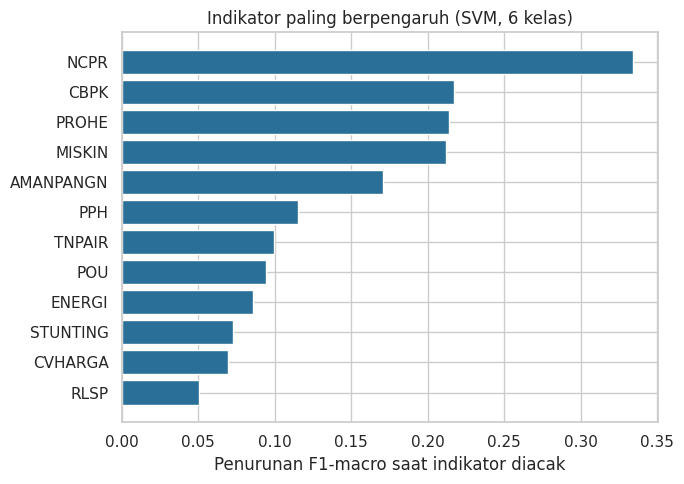

In [9]:
# --------------------------------------------------------------
# 6. INDIKATOR PALING BERPENGARUH (permutation importance, rata-rata 5 fold uji)
# --------------------------------------------------------------
_, imp = nested_cv(X, y6, terbaik6, ambil_importance=True)
imp = pd.Series(imp, index=FITUR).sort_values()
print("\nPentingnya indikator (penurunan F1-macro saat diacak):")
print(imp.sort_values(ascending=False).round(4))
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color="#2a6f97")
ax.set_xlabel("Penurunan F1-macro saat indikator diacak")
ax.set_title("Indikator paling berpengaruh (SVM, 6 kelas)")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()


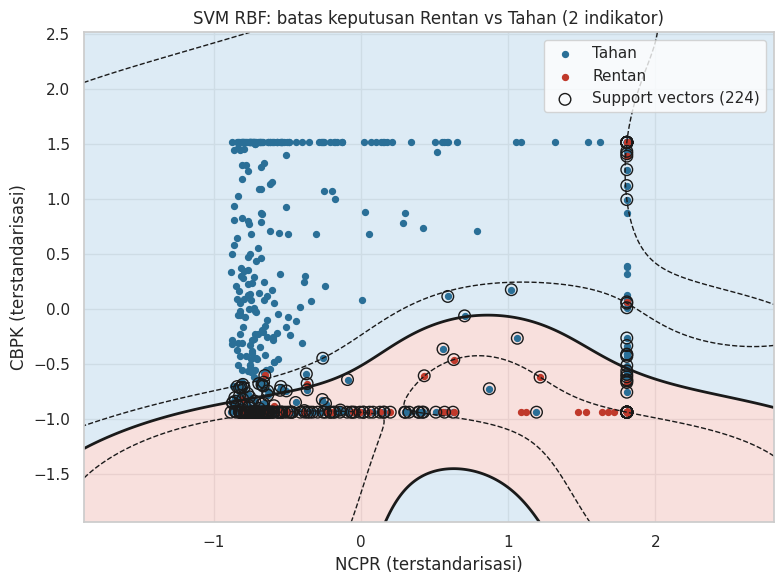

In [10]:
# --------------------------------------------------------------
# 7. VISUALISASI DECISION BOUNDARY (2 indikator terpenting, 2 kelas)
# --------------------------------------------------------------
f1, f2 = imp.index[-1], imp.index[-2]
Xv = StandardScaler().fit_transform(df[[f1, f2]])
yv = (y2 == "Rentan").astype(int).values
svm_v = SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced").fit(Xv, yv)
gx, gy = np.meshgrid(np.linspace(Xv[:, 0].min() - 1, Xv[:, 0].max() + 1, 400),
                     np.linspace(Xv[:, 1].min() - 1, Xv[:, 1].max() + 1, 400))
dec = svm_v.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(gx, gy, dec, levels=[dec.min(), 0, dec.max()],
            colors=["#cfe3f1", "#f6d3cf"], alpha=0.7)
ax.contour(gx, gy, dec, levels=[-1, 0, 1], colors="k",
           linestyles=["--", "-", "--"], linewidths=[1, 2, 1])       # margin & hyperplane
ax.scatter(Xv[yv == 0, 0], Xv[yv == 0, 1], s=18, c="#2a6f97", label="Tahan")
ax.scatter(Xv[yv == 1, 0], Xv[yv == 1, 1], s=18, c="#c0392b", label="Rentan")
ax.scatter(*svm_v.support_vectors_.T, s=70, facecolors="none", edgecolors="k",
           label=f"Support vectors ({len(svm_v.support_vectors_)})")
ax.set_xlabel(f"{f1} (terstandarisasi)"); ax.set_ylabel(f"{f2} (terstandarisasi)")
ax.set_title("SVM RBF: batas keputusan Rentan vs Tahan (2 indikator)")
ax.legend(); plt.tight_layout(); plt.savefig("decision_boundary.png", dpi=150); plt.show()

In [11]:
# --------------------------------------------------------------
# 8. MODEL FINAL (fit di seluruh data) UNTUK DISIMPAN / PREDIKSI BARU
# --------------------------------------------------------------
gs = GridSearchCV(buat_model(terbaik6), PARAM,
                  cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                  scoring="f1_macro", n_jobs=-1).fit(X, y6)
print("\nModel final:", terbaik6, "|", gs.best_params_)
joblib.dump(gs.best_estimator_, "svm_fsva_pkomp.joblib")
# Pakai ulang:  m = joblib.load("svm_fsva_pkomp.joblib"); m.predict(DataFrame_12_indikator)


Model final: Tanpa penanganan | {'svm__C': 1, 'svm__kernel': 'linear'}


['svm_fsva_pkomp.joblib']